In [1]:
import pandas as pd

In [2]:
df = pd.read_excel('Data/Online Retail.xlsx', sheet_name='Online Retail')

In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
df.info()
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


(541909, 8)

In [5]:
df_clean = df[['InvoiceNo', 'Description', 'Quantity']].copy()
rows_before = len(df_clean)
invoices_before = df_clean['InvoiceNo'].nunique()

In [6]:
df_clean = df_clean.dropna(subset=['Description'])
df_clean = df_clean[
    ~df_clean['InvoiceNo'].astype(str).str.startswith('C')
]
df_clean = df_clean[df_clean['Quantity'] > 0]

In [7]:
rows_after = len(df_clean)
invoices_after = df_clean['InvoiceNo'].nunique()

In [8]:
print(f"Jumlah baris sebelum    : {rows_before}")
print(f"Jumlah invoice sebelum  : {invoices_before}")
print(f"Jumlah baris sesudah    : {rows_after}")
print(f"Jumlah invoice sesudah  : {invoices_after}")

Jumlah baris sebelum    : 541909
Jumlah invoice sebelum  : 25900
Jumlah baris sesudah    : 530693
Jumlah invoice sesudah  : 20136


In [9]:
transactions = (df_clean.groupby('InvoiceNo')['Description'].apply(list).tolist())

In [10]:
for i, transaction in enumerate(transactions[:5]):
    print(f"Transaksi {i+1}: {transaction}")

Transaksi 1: ['WHITE HANGING HEART T-LIGHT HOLDER', 'WHITE METAL LANTERN', 'CREAM CUPID HEARTS COAT HANGER', 'KNITTED UNION FLAG HOT WATER BOTTLE', 'RED WOOLLY HOTTIE WHITE HEART.', 'SET 7 BABUSHKA NESTING BOXES', 'GLASS STAR FROSTED T-LIGHT HOLDER']
Transaksi 2: ['HAND WARMER UNION JACK', 'HAND WARMER RED POLKA DOT']
Transaksi 3: ['ASSORTED COLOUR BIRD ORNAMENT', "POPPY'S PLAYHOUSE BEDROOM ", "POPPY'S PLAYHOUSE KITCHEN", 'FELTCRAFT PRINCESS CHARLOTTE DOLL', 'IVORY KNITTED MUG COSY ', 'BOX OF 6 ASSORTED COLOUR TEASPOONS', 'BOX OF VINTAGE JIGSAW BLOCKS ', 'BOX OF VINTAGE ALPHABET BLOCKS', 'HOME BUILDING BLOCK WORD', 'LOVE BUILDING BLOCK WORD', 'RECIPE BOX WITH METAL HEART', 'DOORMAT NEW ENGLAND']
Transaksi 4: ['JAM MAKING SET WITH JARS', 'RED COAT RACK PARIS FASHION', 'YELLOW COAT RACK PARIS FASHION', 'BLUE COAT RACK PARIS FASHION']
Transaksi 5: ['BATH BUILDING BLOCK WORD']


In [11]:
from mlxtend.preprocessing import TransactionEncoder

te = TransactionEncoder()
te.fit(transactions)
te_sparse = te.transform(transactions, sparse=True)
basket = pd.DataFrame.sparse.from_spmatrix(te_sparse, columns=te.columns_)
basket.head()


,4 PURPLE FLOCK DINNER CANDLES,50'S CHRISTMAS GIFT BAG LARGE,DOLLY GIRL BEAKER,I LOVE LONDON MINI BACKPACK,I LOVE LONDON MINI RUCKSACK,NINE DRAWER OFFICE TIDY,OVAL WALL MIRROR DIAMANTE,RED SPOT GIFT BAG LARGE,SET 2 TEA TOWELS I LOVE LONDON,SPACEBOY BABY GIFT SET,...,returned,taig adjust,test,to push order througha s stock was,website fixed,wrongly coded 20713,wrongly coded 23343,wrongly marked,wrongly marked 23343,wrongly sold (22719) barcode
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [15]:
print("Jumlah transaksi :", len(transactions))
print("Ukuran basket    :", basket.shape)
print("Jumlah produk    :", len(te.columns_))
print("Tipe data        :", basket.dtypes.unique())


Jumlah transaksi : 20136
Ukuran basket    : (20136, 4077)
Jumlah produk    : 4077
Tipe data        : [Sparse[bool, False]]


In [13]:
from mlxtend.frequent_patterns import fpgrowth, association_rules

frequent_itemsets = fpgrowth(
    basket, min_support=0.01, use_colnames=True
)
print('Frequent itemsets:', len(frequent_itemsets))

rules = association_rules(
    frequent_itemsets, metric='confidence',
    min_threshold=0.5, num_itemsets=len(basket)
)
rules = rules.sort_values('confidence', ascending=False)
print('Rules:', len(rules))
rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10)


Frequent itemsets: 1854
Rules: 841


,antecedents,consequents,support,confidence,lift
555,"frozenset({SUKI SHOULDER BAG, JAM MAKING SET ...",frozenset({DOTCOM POSTAGE}),0.010379,0.958716,27.266522
372,"frozenset({HERB MARKER THYME, HERB MARKER PARS...",frozenset({HERB MARKER ROSEMARY}),0.010081,0.953052,79.961033
812,"frozenset({REGENCY TEA PLATE ROSES , REGENCY T...",frozenset({REGENCY TEA PLATE GREEN }),0.012664,0.947955,50.099816
371,"frozenset({HERB MARKER ROSEMARY, HERB MARKER P...",frozenset({HERB MARKER THYME}),0.010081,0.944186,80.219959
363,frozenset({HERB MARKER THYME}),frozenset({HERB MARKER ROSEMARY}),0.010975,0.932489,78.235865
575,"frozenset({WOODEN TREE CHRISTMAS SCANDINAVIAN,...",frozenset({WOODEN STAR CHRISTMAS SCANDINAVIAN}),0.011472,0.927711,36.485128
362,frozenset({HERB MARKER ROSEMARY}),frozenset({HERB MARKER THYME}),0.010975,0.920833,78.235865
100,"frozenset({STRAWBERRY CHARLOTTE BAG, CHARLOTTE...",frozenset({RED RETROSPOT CHARLOTTE BAG}),0.012018,0.920152,17.918939
118,"frozenset({CHARLOTTE BAG SUKI DESIGN, STRAWBER...",frozenset({RED RETROSPOT CHARLOTTE BAG}),0.010131,0.918919,17.894924
370,"frozenset({HERB MARKER ROSEMARY, HERB MARKER T...",frozenset({HERB MARKER PARSLEY}),0.010081,0.918552,77.714134


In [14]:
for confidence in [0.3, 0.4, 0.5, 0.6, 0.7]:
    rules_test = association_rules(
        frequent_itemsets,
        metric='confidence',
        min_threshold=confidence,
        num_itemsets=len(basket)
    )

    print(f"Confidence {confidence}: {len(rules_test)} rules")

Confidence 0.3: 1732 rules
Confidence 0.4: 1231 rules
Confidence 0.5: 841 rules
Confidence 0.6: 498 rules
Confidence 0.7: 260 rules


In [16]:
rules_display = rules.copy()
rules_display['antecedents'] = rules_display['antecedents'].apply(lambda x: ', '.join(list(x)))
rules_display['consequents'] = rules_display['consequents'].apply(lambda x: ', '.join(list(x)))
rules_display = rules_display.sort_values(
    by='lift',
    ascending=False
)
rules_display[
    ['antecedents', 'consequents', 'support', 'confidence', 'lift']
]

,antecedents,consequents,support,confidence,lift
371,"HERB MARKER ROSEMARY, HERB MARKER PARSLEY",HERB MARKER THYME,0.010081,0.944186,80.219959
374,HERB MARKER THYME,"HERB MARKER ROSEMARY, HERB MARKER PARSLEY",0.010081,0.856540,80.219959
373,HERB MARKER ROSEMARY,"HERB MARKER THYME, HERB MARKER PARSLEY",0.010081,0.845833,79.961033
372,"HERB MARKER THYME, HERB MARKER PARSLEY",HERB MARKER ROSEMARY,0.010081,0.953052,79.961033
362,HERB MARKER ROSEMARY,HERB MARKER THYME,0.010975,0.920833,78.235865
...,...,...,...,...,...
549,SUKI SHOULDER BAG,JUMBO BAG RED RETROSPOT,0.014005,0.532075,5.121354
378,GREEN REGENCY TEACUP AND SAUCER,REGENCY CAKESTAND 3 TIER,0.025278,0.501478,5.076801
184,TOY TIDY PINK POLKADOT,JUMBO BAG RED RETROSPOT,0.012118,0.520256,5.007587
586,RED RETROSPOT SHOPPER BAG,JUMBO BAG RED RETROSPOT,0.014303,0.500870,4.820989


In [17]:
top_3_rules = rules_display.nlargest(3, 'lift')

display(top_3_rules[
    ['antecedents', 'consequents', 'support', 'confidence', 'lift']
])

,antecedents,consequents,support,confidence,lift
371,"HERB MARKER ROSEMARY, HERB MARKER PARSLEY",HERB MARKER THYME,0.010081,0.944186,80.219959
374,HERB MARKER THYME,"HERB MARKER ROSEMARY, HERB MARKER PARSLEY",0.010081,0.856540,80.219959
373,HERB MARKER ROSEMARY,"HERB MARKER THYME, HERB MARKER PARSLEY",0.010081,0.845833,79.961033


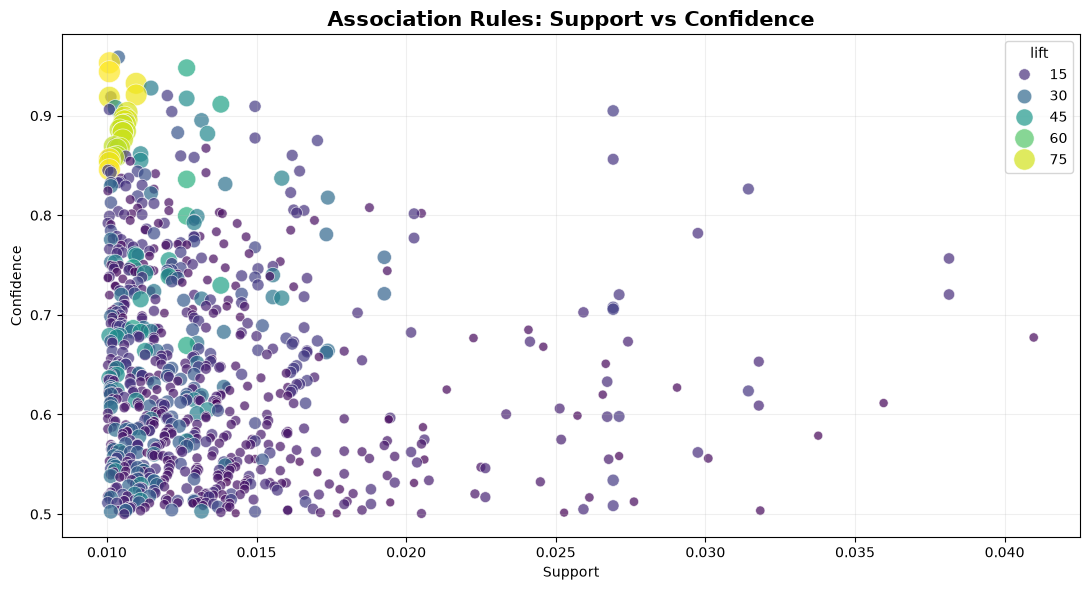

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=rules,
    x='support',
    y='confidence',
    hue='lift',
    size='lift',
    sizes=(40, 250),
    palette='viridis',
    alpha=0.7
)

plt.title('Association Rules: Support vs Confidence',
          fontsize=15, fontweight='bold')
plt.xlabel('Support')
plt.ylabel('Confidence')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

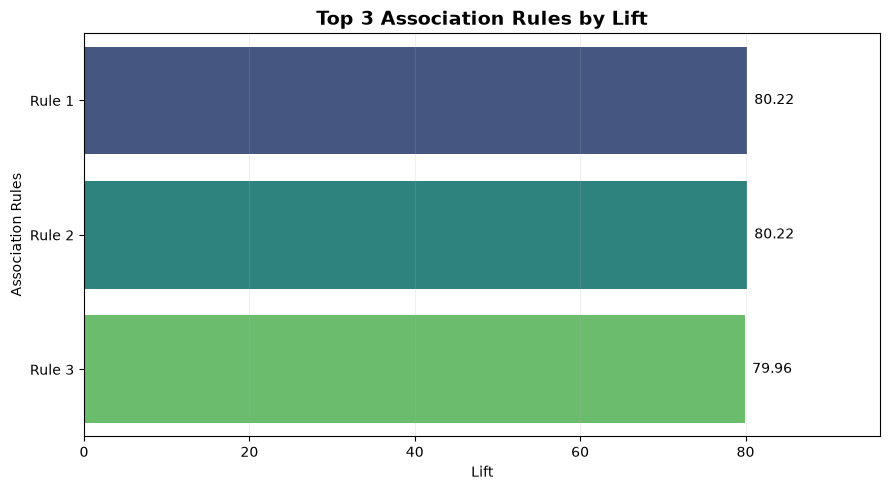

In [24]:
# Singkat label agar tidak terlalu panjang
top3['label'] = ['Rule 1', 'Rule 2', 'Rule 3']

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=top3,
    x='lift',
    y='label',
    hue='label',
    palette='viridis',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=5)

plt.title('Top 3 Association Rules by Lift',
          fontsize=14, fontweight='bold')
plt.xlabel('Lift')
plt.ylabel('Association Rules')
plt.xlim(0, top3['lift'].max() * 1.2)
plt.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()

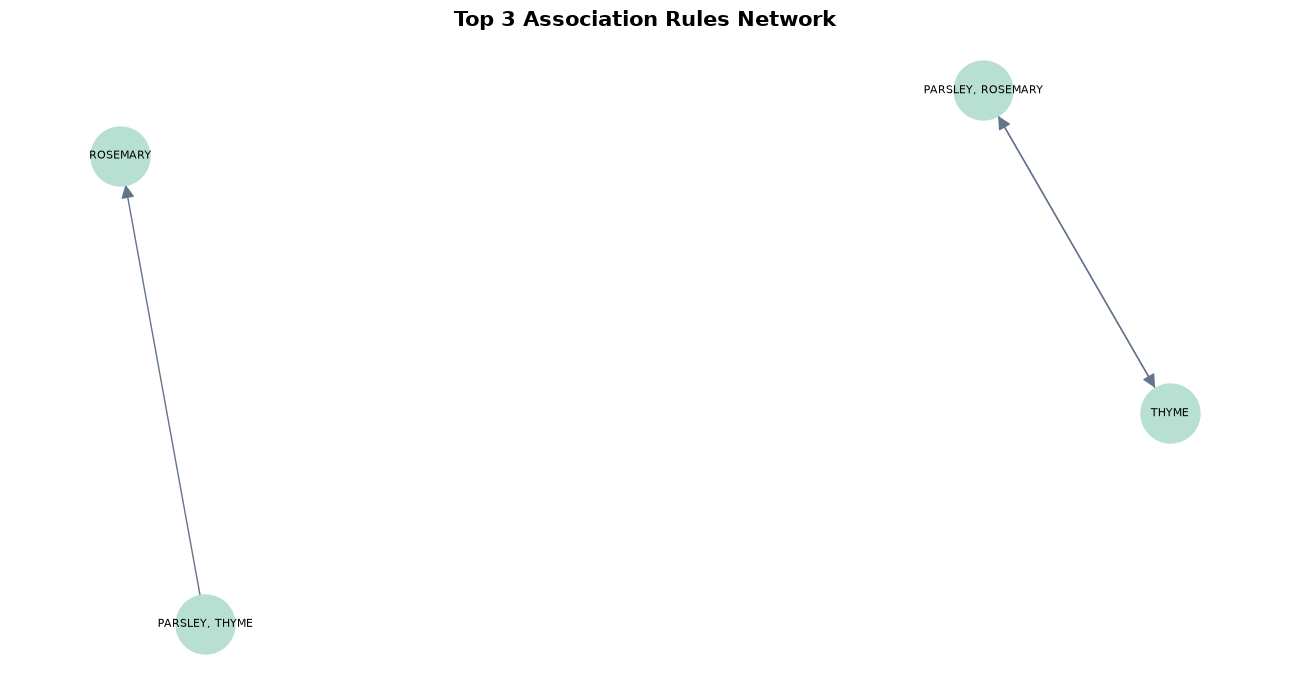

In [25]:
G = nx.DiGraph()

for i, (_, row) in enumerate(top3.iterrows(), start=1):
    source = ', '.join(sorted(row['antecedents']))
    target = ', '.join(sorted(row['consequents']))

    G.add_edge(source, target, lift=row['lift'])

plt.figure(figsize=(13, 7))

pos = nx.spring_layout(G, seed=42, k=1.5)

nx.draw_networkx_nodes(
    G, pos,
    node_color='#B8E0D2',
    node_size=1800
)

nx.draw_networkx_edges(
    G, pos,
    arrows=True,
    arrowsize=20,
    edge_color='#64748B',
    node_size=1800
)

# Label pendek agar tidak bertumpuk
labels = {
    node: node.replace('HERB MARKER ', '')
    for node in G.nodes()
}

nx.draw_networkx_labels(
    G, pos,
    labels=labels,
    font_size=8
)

plt.title('Top 3 Association Rules Network',
          fontsize=15, fontweight='bold')

plt.axis('off')
plt.tight_layout()
plt.show()